<a href="https://colab.research.google.com/github/uchoagab/fixlip/blob/semantic-segmentation-background-influence/semantic_fixlip.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git -C /content/fixlip status
!git -C /content/fixlip pull

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Already up to date.


In [14]:
!git -C /content/fixlip checkout main

Switched to branch 'main'
Your branch is up to date with 'origin/main'.


In [2]:
# ============================================================
# CELL A — Setup
# ============================================================
import subprocess, sys, os, random
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.nn.functional import cosine_similarity
from transformers import (
    CLIPModel, CLIPProcessor,
    SegformerForSemanticSegmentation, SegformerImageProcessor,
)

REPO_URL = "https://github.com/uchoagab/fixlip.git"
REPO_DIR = "/content/fixlip"
if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
else:
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)
os.chdir(REPO_DIR)
sys.path.insert(0, REPO_DIR)

subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "transformers", "accelerate"], check=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


In [3]:
# ============================================================
# CELL B — CLIP + embedding helpers (bulletproof against version drift)
# ============================================================
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
print("visual_projection:", tuple(clip_model.visual_projection.weight.shape))  # (512, 768)
print("text_projection:  ", tuple(clip_model.text_projection.weight.shape))    # (512, 512)


@torch.no_grad()
def get_clip_image_embedding(images):
    """L2-normalized image embeddings, [B, 512]."""
    if isinstance(images, Image.Image):
        images = [images]
    inputs = clip_processor(images=images, return_tensors="pt", padding=True).to(device)
    out = clip_model.vision_model(pixel_values=inputs["pixel_values"])
    pooled = out.pooler_output if out.pooler_output is not None else out.last_hidden_state[:, 0]
    # pooler_output from vision_model is 768-d (unprojected); project it
    if pooled.shape[-1] == clip_model.visual_projection.in_features:
        feats = clip_model.visual_projection(pooled)
    else:
        feats = pooled
    return feats / feats.norm(dim=-1, keepdim=True)


@torch.no_grad()
def get_clip_text_embedding(text):
    """L2-normalized text embedding, [1, 512]."""
    inputs = clip_processor(text=[text], return_tensors="pt",
                            padding=True, truncation=True).to(device)
    out = clip_model.text_model(input_ids=inputs["input_ids"],
                                attention_mask=inputs.get("attention_mask"))
    pooled = out.pooler_output if out.pooler_output is not None else out.last_hidden_state[:, -1]
    feats = clip_model.text_projection(pooled)   # 512 -> 512 learned transform
    return feats / feats.norm(dim=-1, keepdim=True)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

visual_projection: (512, 768)
text_projection:   (512, 512)


In [4]:
# ============================================================
# CELL C — SegFormer + semantic_segmentation (per-image upsampling)
# ============================================================
seg_processor = SegformerImageProcessor.from_pretrained("nvidia/segformer-b0-finetuned-ade-512-512")
seg_model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512").to(device).eval()


@torch.no_grad()
def semantic_segmentation(images, target_classes=None):
    if isinstance(images, Image.Image):
        images = [images]
    inputs = seg_processor(images=images, return_tensors="pt").to(device)
    logits = seg_model(**inputs).logits  # [B, C, H', W']

    masks, pred_ids = [], []
    for i, img in enumerate(images):
        w, h = img.size
        up = torch.nn.functional.interpolate(
            logits[i:i + 1], size=(h, w), mode="bilinear", align_corners=False)
        pred = up.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
        masks.append(pred)
        pred_ids.append(set(np.unique(pred).tolist()))

    if target_classes is not None:
        masks = [np.where(np.isin(m, target_classes), m, 0).astype(np.uint8) for m in masks]
    return masks, pred_ids


def visualize_semantic_segmentation(images, masks, titles=None):
    n = len(images)
    fig, axes = plt.subplots(n, 2, figsize=(8, 4 * n))
    if n == 1:
        axes = axes.reshape(1, -1)
    for i in range(n):
        axes[i, 0].imshow(images[i]); axes[i, 0].set_title(titles[i] if titles else f"Image {i}"); axes[i, 0].axis("off")
        axes[i, 1].imshow(masks[i], cmap="tab20"); axes[i, 1].set_title("Semantic Mask"); axes[i, 1].axis("off")
    plt.tight_layout(); plt.show()

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

In [5]:
# ============================================================
# CELL D — Patch-based embeddings
# ============================================================
def patch_segmentation(images, patch_size=16):
    if isinstance(images, Image.Image):
        images = [images]
    out = []
    for img in images:
        w, h = img.size
        masks = []
        for y in range(0, h, patch_size):
            for x in range(0, w, patch_size):
                m = np.zeros((h, w), dtype=bool)
                m[y:y + patch_size, x:x + patch_size] = True
                masks.append(m)
        out.append(masks)
    return out


@torch.no_grad()
def patch_based_image_embedding(images, patch_size=16):
    if isinstance(images, Image.Image):
        images = [images]
    all_embs = []
    for img in images:
        w, h = img.size
        patches = [img.crop((x, y, min(x + patch_size, w), min(y + patch_size, h)))
                   for y in range(0, h, patch_size)
                   for x in range(0, w, patch_size)]
        feats = get_clip_image_embedding(patches)   # [P, 512]
        emb = feats.mean(dim=0, keepdim=True)
        all_embs.append(emb / emb.norm(dim=-1, keepdim=True))
    return torch.cat(all_embs, dim=0)

In [6]:
# ============================================================
# CELL E — Background influence
# ============================================================
def compute_background_influence(images, text, foreground_classes=None):
    if isinstance(images, Image.Image):
        images = [images]
    masks, _ = semantic_segmentation(images)

    fg_images = []
    for img, mask in zip(images, masks):
        if foreground_classes is not None:
            fg_mask = np.isin(mask, foreground_classes)
        else:
            uniq, counts = np.unique(mask, return_counts=True)
            fg_mask = (mask == uniq[np.argmax(counts)])   # largest region = "foreground"
        arr = np.array(img).copy()
        arr[~fg_mask] = 0
        fg_images.append(Image.fromarray(arr))

    text_emb = get_clip_text_embedding(text)
    orig_sim = (get_clip_image_embedding(images) * text_emb).sum(-1).cpu().numpy()
    fg_sim   = (get_clip_image_embedding(fg_images) * text_emb).sum(-1).cpu().numpy()
    return {
        "original_similarity": orig_sim,
        "foreground_similarity": fg_sim,
        "background_influence": orig_sim - fg_sim,
        "masks": masks,
        "foreground_images": fg_images,
    }

In [7]:
# ============================================================
# CELL F — Patch vs semantic cosine similarity
# ============================================================
@torch.no_grad()
def compare_patch_vs_semantic(images, patch_size=16):
    if isinstance(images, Image.Image):
        images = [images]

    patch_emb = patch_based_image_embedding(images, patch_size=patch_size)  # [B, 512]

    masks, _ = semantic_segmentation(images)
    sem_embs = []
    for img, mask in zip(images, masks):
        arr = np.array(img)
        region_feats = []
        for cls in np.unique(mask):
            rmask = (mask == cls)
            if rmask.sum() < 10:
                continue
            rarr = arr.copy(); rarr[~rmask] = 0
            region_feats.append(get_clip_image_embedding(Image.fromarray(rarr)))
        if region_feats:
            emb = torch.cat(region_feats, dim=0).mean(0, keepdim=True)
        else:
            emb = get_clip_image_embedding(img)
        sem_embs.append(emb / emb.norm(dim=-1, keepdim=True))
    sem_emb = torch.cat(sem_embs, dim=0)

    cos = cosine_similarity(patch_emb, sem_emb, dim=-1)
    return {"cosine_similarity": cos.cpu().numpy(),
            "patch_embeddings": patch_emb,
            "semantic_embeddings": sem_emb}

Image 0: PIL(W,H)=(512, 373), mask(H,W)=(373, 512)
Image 1: PIL(W,H)=(424, 424), mask(H,W)=(424, 424)
Image 2: PIL(W,H)=(512, 287), mask(H,W)=(287, 512)


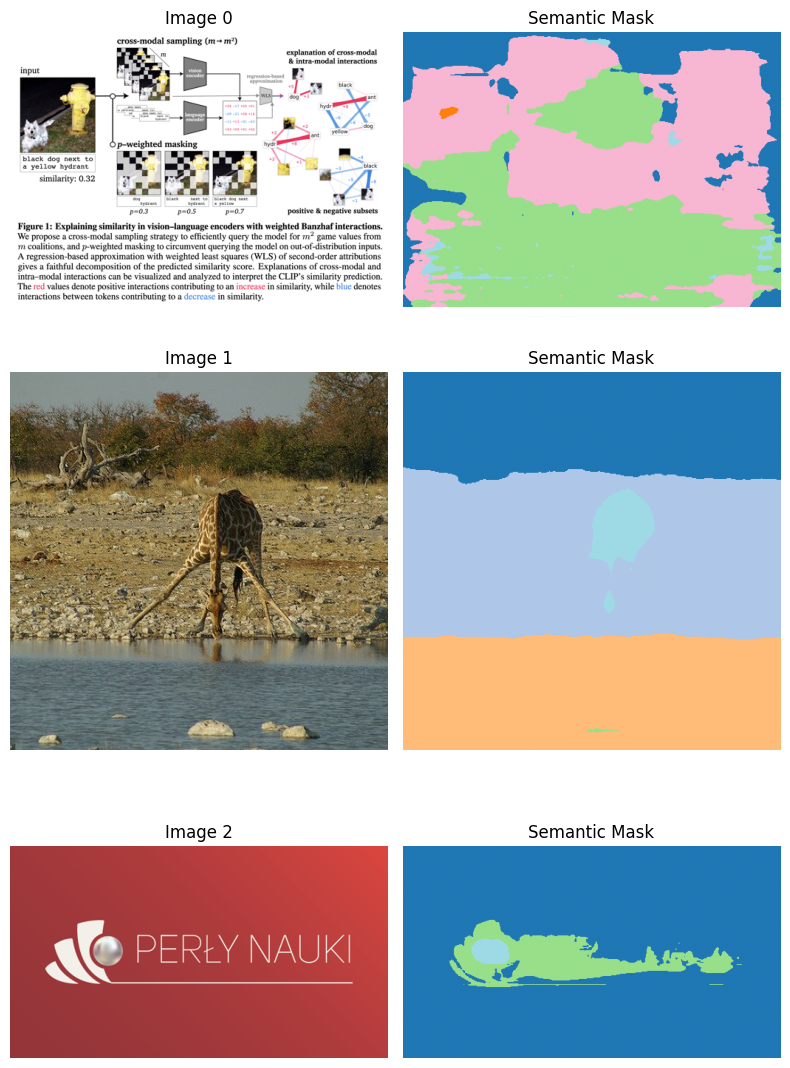


===== Background Influence =====
Image 0: orig=0.1804  fg=0.2081  bg_influence=-0.0278
Image 1: orig=0.2395  fg=0.2666  bg_influence=-0.0271
Image 2: orig=0.1874  fg=0.2132  bg_influence=-0.0258


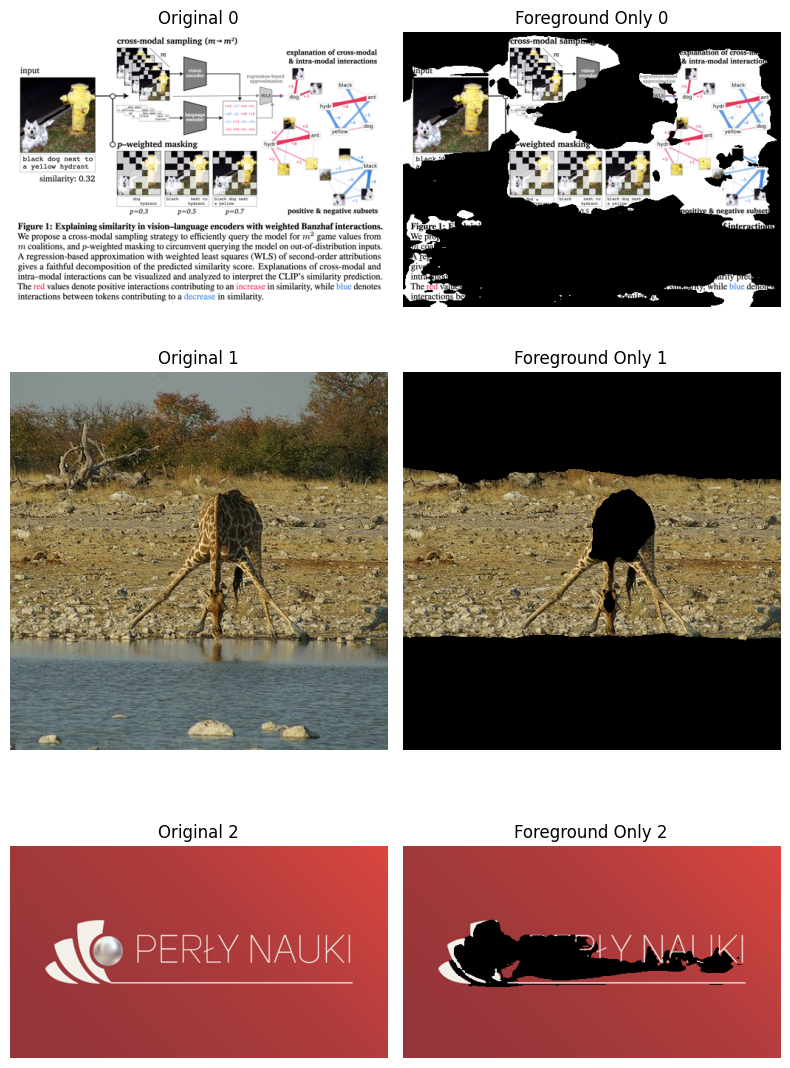


===== Patch vs Semantic Cosine Similarity =====
Image 0: cosine_sim = 0.8836
Image 1: cosine_sim = 0.8670
Image 2: cosine_sim = 0.8432


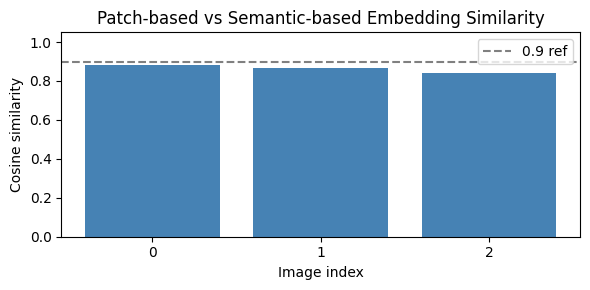

In [8]:
# ============================================================
# CELL G — Main: pick 3 random images & visualize everything
# ============================================================
image_pool = []
assets_dir = os.path.join(REPO_DIR, "assets")
if os.path.exists(assets_dir):
    for f in os.listdir(assets_dir):
        if f.lower().endswith((".png", ".jpg", ".jpeg")):
            image_pool.append(Image.open(os.path.join(assets_dir, f)).convert("RGB"))
while len(image_pool) < 3:
    image_pool.append(Image.fromarray(np.random.randint(0, 255, (224, 224, 3), dtype=np.uint8)))

random.seed(0)
selected_images = random.sample(image_pool, 3)

# Downscale to max 512 on long side — prevents SegFormer OOM
def shrink(imgs, max_side=512):
    out = []
    for im in imgs:
        w, h = im.size
        s = min(1.0, max_side / max(w, h))
        if s < 1.0:
            im = im.resize((int(w * s), int(h * s)), Image.BICUBIC)
        out.append(im.convert("RGB"))
    return out
selected_images = shrink(selected_images)

TEXT_QUERY = "a photo of an object"  # <-- change to your text

# --- shape sanity ---
masks, _ = semantic_segmentation(selected_images)
for i, (img, m) in enumerate(zip(selected_images, masks)):
    print(f"Image {i}: PIL(W,H)={img.size}, mask(H,W)={m.shape}")
    assert m.shape == (img.size[1], img.size[0])

# --- 1) semantic segmentation ---
visualize_semantic_segmentation(selected_images, masks, titles=[f"Image {i}" for i in range(3)])

# --- 2) background influence ---
bg = compute_background_influence(selected_images, TEXT_QUERY)
print("\n===== Background Influence =====")
for i in range(3):
    print(f"Image {i}: orig={bg['original_similarity'][i]:.4f}  "
          f"fg={bg['foreground_similarity'][i]:.4f}  "
          f"bg_influence={bg['background_influence'][i]:.4f}")

fig, axes = plt.subplots(3, 2, figsize=(8, 12))
for i in range(3):
    axes[i, 0].imshow(selected_images[i]); axes[i, 0].set_title(f"Original {i}"); axes[i, 0].axis("off")
    axes[i, 1].imshow(bg["foreground_images"][i]); axes[i, 1].set_title(f"Foreground Only {i}"); axes[i, 1].axis("off")
plt.tight_layout(); plt.show()

# --- 3) patch vs semantic ---
cmp = compare_patch_vs_semantic(selected_images)
print("\n===== Patch vs Semantic Cosine Similarity =====")
for i in range(3):
    print(f"Image {i}: cosine_sim = {cmp['cosine_similarity'][i]:.4f}")

plt.figure(figsize=(6, 3))
plt.bar(range(3), cmp["cosine_similarity"], color="steelblue")
plt.axhline(y=0.9, color="gray", ls="--", label="0.9 ref")
plt.xlabel("Image index"); plt.ylabel("Cosine similarity")
plt.title("Patch-based vs Semantic-based Embedding Similarity")
plt.xticks(range(3)); plt.ylim(0, 1.05); plt.legend(); plt.tight_layout(); plt.show()

# Older Versions (Not Working)

In [16]:
# ============================================================
# CELL 1: Environment setup — clone fork & install dependencies
# ============================================================
import subprocess, sys, os

REPO_URL = "https://github.com/uchoagab/fixlip.git"
REPO_DIR = "/content/fixlip"

if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
else:
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)

os.chdir(REPO_DIR)
sys.path.insert(0, REPO_DIR)   # make sure we can `import src`

subprocess.run([
    sys.executable, "-m", "pip", "install", "-q",
    "torch", "torchvision", "transformers", "accelerate",
    "shapiq", "matplotlib", "numpy", "pillow", "tqdm"
], check=True)

print("Environment ready, current directory:", os.getcwd())

Environment ready, current directory: /content/fixlip


In [17]:
# ============================================================
# CELL 2 (v3 — bulletproof, bypasses get_*_features entirely)
# ============================================================
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.nn.functional import cosine_similarity
from transformers import CLIPModel, CLIPProcessor

print("Cell 2 v3 loaded - bulletproof version")   # <-- confirm this prints

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Sanity: check projection layer shapes once
print("visual_projection weight shape:", clip_model.visual_projection.weight.shape)  # expect [512, 768]
print("text_projection weight shape:  ", clip_model.text_projection.weight.shape)    # expect [512, 512]


@torch.no_grad()
def get_clip_image_embedding(images):
    """
    Get CLIP image embeddings for a batch. Returns L2-normalized vectors of shape [B, 512].
    Bypasses get_image_features so we control the projection step explicitly.
    """
    if isinstance(images, Image.Image):
        images = [images]
    inputs = clip_processor(images=images, return_tensors="pt", padding=True).to(device)

    # Run the vision encoder directly
    vision_out = clip_model.vision_model(pixel_values=inputs["pixel_values"])
    pooled = vision_out.pooler_output
    if pooled is None:
        pooled = vision_out.last_hidden_state[:, 0]   # fallback: CLS token

    # pooler_output is [B, 768] (unprojected) in standard CLIP ViT-B/32.
    # Project to [B, 512] only if the pooler is still at in_features dim.
    in_features = clip_model.visual_projection.weight.shape[1]   # 768
    if pooled.shape[-1] == in_features:
        feats = clip_model.visual_projection(pooled)
    else:
        # Already at 512 (some transformers versions pre-project it)
        feats = pooled

    feats = feats / feats.norm(dim=-1, keepdim=True)
    return feats


@torch.no_grad()
def get_clip_text_embedding(text):
    """
    Get CLIP text embedding. Returns an L2-normalized vector of shape [1, 512].
    Text pooler_output is the EOT token, [1, 512] unprojected; we always apply text_projection.
    """
    inputs = clip_processor(
        text=[text], return_tensors="pt", padding=True, truncation=True
    ).to(device)

    text_out = clip_model.text_model(
        input_ids=inputs["input_ids"],
        attention_mask=inputs.get("attention_mask"),
    )
    pooled = text_out.pooler_output
    if pooled is None:
        pooled = text_out.last_hidden_state[:, -1]

    # text_projection is 512 -> 512 (a real learned transform, not identity)
    feats = clip_model.text_projection(pooled)
    feats = feats / feats.norm(dim=-1, keepdim=True)
    return feats

Cell 2 v3 loaded - bulletproof version
Using device: cpu


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

visual_projection weight shape: torch.Size([512, 768])
text_projection weight shape:   torch.Size([512, 512])


In [18]:
# ============================================================
# CELL 3 (v2 — per-image upsampling; fixes IndexError)
# ============================================================
print("Cell 3 v2 loaded - per-image upsampling")   # <-- confirm this prints

from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

seg_processor = SegformerImageProcessor.from_pretrained("nvidia/segformer-b0-finetuned-ade-512-512")
seg_model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512"
).to(device).eval()


@torch.no_grad()
def semantic_segmentation(images, target_classes=None):
    """
    Perform semantic segmentation on a batch of images of arbitrary sizes.
    Returns per-image masks (numpy [H_i, W_i]) and the set of predicted label ids.
    """
    if isinstance(images, Image.Image):
        images = [images]

    inputs = seg_processor(images=images, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = seg_model(**inputs)
        logits = outputs.logits  # [B, num_labels, H', W']

    masks, all_pred_ids = [], []
    for i, img in enumerate(images):
        w, h = img.size                                # PIL size is (W, H)
        up = torch.nn.functional.interpolate(
            logits[i:i + 1],                           # keep batch dim
            size=(h, w),                               # (H, W) for interpolate
            mode="bilinear",
            align_corners=False,
        )
        pred = up.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
        masks.append(pred)
        all_pred_ids.append(set(np.unique(pred).tolist()))

    if target_classes is not None:
        filtered_masks = []
        for m in masks:
            m2 = np.zeros_like(m)
            for c in target_classes:
                m2[m == c] = c
            filtered_masks.append(m2)
        return filtered_masks, all_pred_ids

    return masks, all_pred_ids

Cell 3 v2 loaded - per-image upsampling


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

In [ ]:
# ============================================================
# CELL 3 (v2 — per-image upsampling; fixes IndexError)
# ============================================================
print("Cell 3 v2 loaded - per-image upsampling")   # <-- confirm this prints

from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

seg_processor = SegformerImageProcessor.from_pretrained("nvidia/segformer-b0-finetuned-ade-512-512")
seg_model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512"
).to(device).eval()


@torch.no_grad()
def semantic_segmentation(images, target_classes=None):
    """
    Perform semantic segmentation on a batch of images of arbitrary sizes.
    Returns per-image masks (numpy [H_i, W_i]) and the set of predicted label ids.
    """
    if isinstance(images, Image.Image):
        images = [images]

    inputs = seg_processor(images=images, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = seg_model(**inputs)
        logits = outputs.logits  # [B, num_labels, H', W']

    masks, all_pred_ids = [], []
    for i, img in enumerate(images):
        w, h = img.size                                # PIL size is (W, H)
        up = torch.nn.functional.interpolate(
            logits[i:i + 1],                           # keep batch dim
            size=(h, w),                               # (H, W) for interpolate
            mode="bilinear",
            align_corners=False,
        )
        pred = up.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
        masks.append(pred)
        all_pred_ids.append(set(np.unique(pred).tolist()))

    if target_classes is not None:
        filtered_masks = []
        for m in masks:
            m2 = np.zeros_like(m)
            for c in target_classes:
                m2[m == c] = c
            filtered_masks.append(m2)
        return filtered_masks, all_pred_ids

    return masks, all_pred_ids

In [19]:
# ============================================================
# CELL 4: Patch segmentation function (mimics FIxLIP's patch splitting)
# ============================================================
def patch_segmentation(images, patch_size=16):
    """
    Split images into non-overlapping patch_size × patch_size patches.
    Returns: patch_masks (list[list[np.ndarray]]) — for each image, a list of boolean masks,
             each mask selecting one patch.
    """
    if isinstance(images, Image.Image):
        images = [images]
    all_patch_masks = []
    for img in images:
        w, h = img.size
        masks = []
        for y in range(0, h, patch_size):
            for x in range(0, w, patch_size):
                mask = np.zeros((h, w), dtype=bool)
                mask[y:y + patch_size, x:x + patch_size] = True
                masks.append(mask)
        all_patch_masks.append(masks)
    return all_patch_masks


def patch_based_image_embedding(images, patch_size=16):
    """
    Compute patch-based image embeddings:
    encode each patch separately with CLIP, then average them into one image representation.
    Returns: patch-based embeddings of shape [B, D].
    """
    if isinstance(images, Image.Image):
        images = [images]
    all_embeddings = []
    for img in images:
        w, h = img.size
        patch_imgs = []
        for y in range(0, h, patch_size):
            for x in range(0, w, patch_size):
                patch = img.crop((x, y, min(x + patch_size, w), min(y + patch_size, h)))
                patch_imgs.append(patch)
        # Encode all patches in one batch
        with torch.no_grad():
            inputs = clip_processor(images=patch_imgs, return_tensors="pt", padding=True).to(device)
            feats = clip_model.get_image_features(**inputs)
            feats = feats / feats.norm(dim=-1, keepdim=True)
        # Average-pool to get the whole-image representation
        img_emb = feats.mean(dim=0, keepdim=True)  # [1, D]
        all_embeddings.append(img_emb)
    return torch.cat(all_embeddings, dim=0)  # [B, D]

In [20]:
# ============================================================
# CELL 5: Background influence function (batch)
# ============================================================
def compute_background_influence(images, text, foreground_classes=None):
    """
    Measure how much the background contributes to the CLIP image-text similarity.
    Method: compute similarity on the original image and on a foreground-only image
            (background zeroed out). The difference is the background's contribution.
    foreground_classes: if None, use the largest semantic region as foreground.
    Returns: dict with per-image original similarity, foreground similarity,
             and background influence.
    """
    if isinstance(images, Image.Image):
        images = [images]

    # 1) Get semantic masks
    masks, pred_ids = semantic_segmentation(images)

    # 2) Build foreground-only images (background painted black)
    fg_images = []
    for img, mask, ids in zip(images, masks, pred_ids):
        if foreground_classes is not None:
            fg_mask = np.isin(mask, foreground_classes)
        else:
            # Automatically choose the largest region as foreground
            unique, counts = np.unique(mask, return_counts=True)
            largest_class = unique[np.argmax(counts)]
            fg_mask = (mask == largest_class)

        img_arr = np.array(img).copy()
        img_arr[~fg_mask] = 0  # paint background black
        fg_images.append(Image.fromarray(img_arr))

    # 3) Compute CLIP similarities in batch
    text_emb = get_clip_text_embedding(text)                  # [1, D]
    orig_emb = get_clip_image_embedding(images)                # [B, D]
    fg_emb = get_clip_image_embedding(fg_images)               # [B, D]

    orig_sim = (orig_emb * text_emb).sum(dim=-1).cpu().numpy()  # [B]
    fg_sim = (fg_emb * text_emb).sum(dim=-1).cpu().numpy()      # [B]
    bg_influence = orig_sim - fg_sim                             # [B]

    return {
        "original_similarity": orig_sim,
        "foreground_similarity": fg_sim,
        "background_influence": bg_influence,
        "masks": masks,
        "foreground_images": fg_images,
    }

In [21]:
# ============================================================
# CELL 6: Patch vs Semantic cosine similarity (batch)
# ============================================================
def compare_patch_vs_semantic(images, patch_size=16):
    """
    Compare patch-based embeddings with semantic-based embeddings via cosine similarity.
    Semantic-based embedding: run SegFormer to get a semantic map, then encode each
    semantic region with CLIP and average the region embeddings.
    Returns: cosine_sim [B], and both embedding sets.
    """
    if isinstance(images, Image.Image):
        images = [images]

    # Patch-based embedding
    patch_emb = patch_based_image_embedding(images, patch_size=patch_size)  # [B, D]

    # Semantic-based embedding
    masks, _ = semantic_segmentation(images)
    semantic_embs = []
    for img, mask in zip(images, masks):
        unique_classes = np.unique(mask)
        region_embeddings = []
        img_arr = np.array(img)
        for cls in unique_classes:
            region_mask = (mask == cls)
            if region_mask.sum() < 10:  # ignore tiny regions
                continue
            region_img_arr = img_arr.copy()
            region_img_arr[~region_mask] = 0
            region_img = Image.fromarray(region_img_arr)
            with torch.no_grad():
                inputs = clip_processor(images=[region_img], return_tensors="pt").to(device)
                feat = clip_model.get_image_features(**inputs)
                feat = feat / feat.norm(dim=-1, keepdim=True)
            region_embeddings.append(feat)

        if len(region_embeddings) == 0:
            # Fallback to whole-image embedding if no valid region exists
            semantic_embs.append(get_clip_image_embedding([img]))
        else:
            stacked = torch.cat(region_embeddings, dim=0)  # [R, D]
            sem_emb = stacked.mean(dim=0, keepdim=True)     # [1, D]
            sem_emb = sem_emb / sem_emb.norm(dim=-1, keepdim=True)
            semantic_embs.append(sem_emb)

    semantic_emb = torch.cat(semantic_embs, dim=0)  # [B, D]

    # Per-sample cosine similarity
    cos_sims = cosine_similarity(patch_emb, semantic_emb, dim=-1)  # [B]

    return {
        "cosine_similarity": cos_sims.cpu().numpy(),
        "patch_embeddings": patch_emb,
        "semantic_embeddings": semantic_emb,
    }

In [22]:
# ============================================================
# DIAGNOSTIC: run each step of Cell 7 separately
# ============================================================
import traceback, gc, torch

def step(name, fn):
    print(f"\n===== {name} =====")
    try:
        result = fn()
        print(f"[OK] {name}")
        return result
    except Exception as e:
        print(f"[FAIL] {name}: {type(e).__name__}: {e}")
        traceback.print_exc()
        return None

# 0) Sanity: inputs
step("inputs", lambda: (
    print("n images:", len(selected_images)),
    print("sizes:", [im.size for im in selected_images]),
    print("modes:", [im.mode for im in selected_images]),
    print("TEXT_QUERY:", TEXT_QUERY),
)[0])

# 1) Semantic segmentation only
sem = step("semantic_segmentation",
           lambda: semantic_segmentation(selected_images))
if sem is not None:
    masks, _ = sem
    for i, (img, m) in enumerate(zip(selected_images, masks)):
        print(f"  image {i}: PIL(W,H)={img.size}, mask(H,W)={m.shape}, "
              f"labels={sorted(set(m.flatten().tolist()))[:10]}")
    del sem; gc.collect()

# 2) Text embedding only
step("text embedding",
     lambda: print("text emb shape:", get_clip_text_embedding(TEXT_QUERY).shape))

# 3) Image embeddings only
step("image embedding",
     lambda: print("img emb shape:", get_clip_image_embedding(selected_images).shape))

# 4) Background influence (full)
bg = step("compute_background_influence",
          lambda: compute_background_influence(selected_images, TEXT_QUERY))

# 5) Patch vs semantic (full) — memory-heavy, run last
cmp = step("compare_patch_vs_semantic",
           lambda: compare_patch_vs_semantic(selected_images))
if cmp is not None:
    print("cosine sims:", cmp["cosine_similarity"])

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


===== inputs =====
[FAIL] inputs: NameError: name 'selected_images' is not defined

===== semantic_segmentation =====
[FAIL] semantic_segmentation: NameError: name 'selected_images' is not defined

===== text embedding =====
[FAIL] text embedding: NameError: name 'TEXT_QUERY' is not defined

===== image embedding =====
[FAIL] image embedding: NameError: name 'selected_images' is not defined

===== compute_background_influence =====
[FAIL] compute_background_influence: NameError: name 'selected_images' is not defined

===== compare_patch_vs_semantic =====
[FAIL] compare_patch_vs_semantic: NameError: name 'selected_images' is not defined


Traceback (most recent call last):
  File "/tmp/ipykernel_180/4265624352.py", line 9, in step
    result = fn()
  File "/tmp/ipykernel_180/4265624352.py", line 19, in <lambda>
    print("n images:", len(selected_images)),
                           ^^^^^^^^^^^^^^^
NameError: name 'selected_images' is not defined
Traceback (most recent call last):
  File "/tmp/ipykernel_180/4265624352.py", line 9, in step
    result = fn()
  File "/tmp/ipykernel_180/4265624352.py", line 27, in <lambda>
    lambda: semantic_segmentation(selected_images))
                                  ^^^^^^^^^^^^^^^
NameError: name 'selected_images' is not defined
Traceback (most recent call last):
  File "/tmp/ipykernel_180/4265624352.py", line 9, in step
    result = fn()
  File "/tmp/ipykernel_180/4265624352.py", line 37, in <lambda>
    lambda: print("text emb shape:", get_clip_text_embedding(TEXT_QUERY).shape))
                                                             ^^^^^^^^^^
NameError: name 'TEXT_QUERY' i

In [ ]:
# ============================================================
# CELL 7: Randomly pick 3 images & visualize all results
# ============================================================
import random

# -------- Build the image pool --------
# You can drop any number of PIL.Image objects into image_pool.
# Here we use the repo's assets folder, then add placeholders if needed.
image_pool = []

assets_dir = os.path.join(REPO_DIR, "assets")
if os.path.exists(assets_dir):
    for fname in os.listdir(assets_dir):
        if fname.lower().endswith((".png", ".jpg", ".jpeg")):
            image_pool.append(Image.open(os.path.join(assets_dir, fname)).convert("RGB"))

# If assets has fewer than 3 images, generate random colored placeholders
while len(image_pool) < 3:
    arr = np.random.randint(0, 255, (224, 224, 3), dtype=np.uint8)
    image_pool.append(Image.fromarray(arr))

# -------- Randomly pick 3 --------
random.seed(0)  # reproducible
selected_images = random.sample(image_pool, 3)

TEXT_QUERY = "a photo of an object"   # replace with the text description you care about

print(f"Randomly selected {len(selected_images)} images")
for i, img in enumerate(selected_images):
    print(f"  Image {i}: size={img.size}")

# -------- 1) Visualize semantic segmentation --------
sem_masks, _ = semantic_segmentation(selected_images)
visualize_semantic_segmentation(selected_images, sem_masks,
                                titles=[f"Image {i}" for i in range(3)])

# -------- 2) Background influence --------
bg_result = compute_background_influence(selected_images, TEXT_QUERY)
print("\n===== Background Influence =====")
for i in range(len(selected_images)):
    print(f"Image {i}: original_sim={bg_result['original_similarity'][i]:.4f}, "
          f"fg_sim={bg_result['foreground_similarity'][i]:.4f}, "
          f"bg_influence={bg_result['background_influence'][i]:.4f}")

# Visualization: original vs foreground-only
fig, axes = plt.subplots(len(selected_images), 2, figsize=(8, 4 * len(selected_images)))
if len(selected_images) == 1:
    axes = axes.reshape(1, -1)
for i in range(len(selected_images)):
    axes[i, 0].imshow(selected_images[i])
    axes[i, 0].set_title(f"Original {i}")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(bg_result["foreground_images"][i])
    axes[i, 1].set_title(f"Foreground Only {i}")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

# -------- 3) Patch vs Semantic cosine similarity --------
cmp_result = compare_patch_vs_semantic(selected_images)
print("\n===== Patch vs Semantic Cosine Similarity =====")
for i in range(len(selected_images)):
    print(f"Image {i}: cosine_sim = {cmp_result['cosine_similarity'][i]:.4f}")

# Visualize cosine similarity
plt.figure(figsize=(6, 3))
plt.bar(range(len(selected_images)), cmp_result["cosine_similarity"], color="steelblue")
plt.axhline(y=0.9, color="gray", linestyle="--", label="0.9 reference")
plt.xlabel("Image index")
plt.ylabel("Cosine similarity")
plt.title("Patch-based vs Semantic-based Embedding Similarity")
plt.xticks(range(len(selected_images)))
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

#Previous Checks

In [ ]:
#After Cell 2
t = get_clip_text_embedding("a photo of a dog")
i = get_clip_image_embedding(selected_images)
print("text:", t.shape, "image:", i.shape)   # expect (1, 512) and (3, 512)
print("text norm:", t.norm().item())          # expect ~1.0
print("image norms:", i.norm(dim=-1))         # expect ~1.0 each

In [ ]:
t = get_clip_text_embedding("a photo of a dog")
i = get_clip_image_embedding(selected_images)
print("text:", t.shape, "image:", i.shape)   # expect (1, 512) and (3, 512)
print("text norm:", t.norm().item())          # ~1.0
print("image norms:", i.norm(dim=-1))         # ~1.0 each

In [ ]:
#After Cell 3
masks, _ = semantic_segmentation(selected_images)
for i, (img, m) in enumerate(zip(selected_images, masks)):
    print(f"Image {i}: PIL={img.size[::-1]}, mask={m.shape}")
    assert m.shape == (img.size[1], img.size[0]), "shape mismatch"

In [ ]:
t = get_clip_text_embedding("a photo of a dog")
i = get_clip_image_embedding(selected_images)
print("text:", t.shape, "image:", i.shape)   # expect (1, 512) and (3, 512)
print("text norm:", t.norm().item())          # ~1.0
print("image norms:", i.norm(dim=-1))         # ~1.0 each

In [ ]:
import inspect
print("Cell 3 v2 loaded" in inspect.getsource(semantic_segmentation) or
      "print" in inspect.getsource(semantic_segmentation))
# Simpler: just check the actual output
masks, _ = semantic_segmentation(selected_images)
for i, (img, m) in enumerate(zip(selected_images, masks)):
    print(f"Image {i}: PIL(W,H)={img.size}, mask(H,W)={m.shape}")

In [ ]:
# Downscale inputs to a max side of 512 (speeds up segmentation, saves memory)
def shrink(imgs, max_side=512):
    out = []
    for im in imgs:
        w, h = im.size
        s = min(1.0, max_side / max(w, h))
        if s < 1.0:
            im = im.resize((int(w * s), int(h * s)), Image.BICUBIC)
        out.append(im.convert("RGB"))
    return out

selected_images = shrink(selected_images)
print("resized to:", [im.size for im in selected_images])

In [ ]:
masks, _ = semantic_segmentation(selected_images)
for i, (img, m) in enumerate(zip(selected_images, masks)):
    print(f"Image {i}: PIL(W,H)={img.size}, mask(H,W)={m.shape}")
    assert m.shape == (img.size[1], img.size[0]), "shape mismatch — still running old v1"

#Even Older Versions

In [ ]:
# ============================================================
# CELL 2: Load the CLIP model & define basic utilities
# ============================================================
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.nn.functional import cosine_similarity
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")


@torch.no_grad()
def get_clip_image_embedding(images):
    """
    Get CLIP image embeddings for a batch. Returns L2-normalized vectors of shape [B, D].
    images: list[PIL.Image] or a single PIL.Image
    """
    if isinstance(images, Image.Image):
        images = [images]
    inputs = clip_processor(images=images, return_tensors="pt", padding=True).to(device)
    feats = clip_model.get_image_features(**inputs)          # [B, D]
    feats = feats / feats.norm(dim=-1, keepdim=True)         # L2 normalize
    return feats


@torch.no_grad()
def get_clip_text_embedding(text):
    """Get CLIP text embedding. Returns an L2-normalized vector of shape [1, D]."""
    inputs = clip_processor(text=[text], return_tensors="pt", padding=True).to(device)
    feats = clip_model.get_text_features(**inputs)
    feats = feats / feats.norm(dim=-1, keepdim=True)
    return feats

In [ ]:
# ============================================================
# CELL 2 (FIXED): Load the CLIP model & define basic utilities
# ============================================================
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.nn.functional import cosine_similarity
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")


def _to_feature_tensor(out, projection_layer):
    """
    Some transformers versions return a tensor from get_text_features/get_image_features,
    others return a BaseModelOutputWithPooling. Normalize both cases to a projected tensor.
    """
    if isinstance(out, torch.Tensor):
        return out
    # BaseModelOutputWithPooling-like -> project the pooled output
    if hasattr(out, "pooler_output") and out.pooler_output is not None:
        return projection_layer(out.pooler_output)
    if hasattr(out, "last_hidden_state") and out.last_hidden_state is not None:
        return projection_layer(out.last_hidden_state[:, 0])
    raise TypeError(f"Unexpected output type from CLIP: {type(out)}")


@torch.no_grad()
def get_clip_image_embedding(images):
    """
    Get CLIP image embeddings for a batch. Returns L2-normalized vectors of shape [B, D].
    images: list[PIL.Image] or a single PIL.Image
    """
    if isinstance(images, Image.Image):
        images = [images]
    inputs = clip_processor(images=images, return_tensors="pt", padding=True).to(device)
    out = clip_model.get_image_features(**inputs)
    feats = _to_feature_tensor(out, clip_model.visual_projection)   # [B, D]
    feats = feats / feats.norm(dim=-1, keepdim=True)                # L2 normalize
    return feats


@torch.no_grad()
def get_clip_text_embedding(text):
    """Get CLIP text embedding. Returns an L2-normalized vector of shape [1, D]."""
    inputs = clip_processor(
        text=[text], return_tensors="pt", padding=True, truncation=True
    ).to(device)
    out = clip_model.get_text_features(**inputs)
    feats = _to_feature_tensor(out, clip_model.text_projection)     # [1, D]
    feats = feats / feats.norm(dim=-1, keepdim=True)
    return feats

In [ ]:
# ============================================================
# CELL 2 (FIXED AGAIN): Load the CLIP model & define basic utilities
# ============================================================
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from torch.nn.functional import cosine_similarity
from transformers import CLIPModel, CLIPProcessor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")


def _to_feature_tensor(out, projection_layer):
    """
    Normalize the return value of get_text_features / get_image_features into a
    projected tensor, across transformers versions.

    - New API: returns a Tensor already in projection space -> use as-is.
    - Old API: returns BaseModelOutputWithPooling -> pool the output and project,
      unless the pooled tensor is already at projection_dim and the layer's
      in_features != out_features (which signals "someone already projected this").
    """
    if isinstance(out, torch.Tensor):
        # Already the projected embedding (modern transformers behavior).
        return out

    if hasattr(out, "pooler_output") and out.pooler_output is not None:
        feats = out.pooler_output
    elif hasattr(out, "last_hidden_state") and out.last_hidden_state is not None:
        feats = out.last_hidden_state[:, 0]
    else:
        raise TypeError(f"Unexpected output type from CLIP: {type(out)}")

    # If the pooled tensor already matches projection_dim AND the projection
    # layer actually reduces dimensionality (in != out, e.g. 768->512 for vision),
    # then it's already been projected -> return as-is.
    if (feats.shape[-1] == projection_layer.out_features
            and projection_layer.in_features != projection_layer.out_features):
        return feats

    return projection_layer(feats)


@torch.no_grad()
def get_clip_image_embedding(images):
    """
    Get CLIP image embeddings for a batch. Returns L2-normalized vectors of shape [B, D].
    images: list[PIL.Image] or a single PIL.Image
    """
    if isinstance(images, Image.Image):
        images = [images]
    inputs = clip_processor(images=images, return_tensors="pt", padding=True).to(device)
    out = clip_model.get_image_features(**inputs)
    feats = _to_feature_tensor(out, clip_model.visual_projection)   # [B, D]
    feats = feats / feats.norm(dim=-1, keepdim=True)                # L2 normalize
    return feats


@torch.no_grad()
def get_clip_text_embedding(text):
    """Get CLIP text embedding. Returns an L2-normalized vector of shape [1, D]."""
    inputs = clip_processor(
        text=[text], return_tensors="pt", padding=True, truncation=True
    ).to(device)
    out = clip_model.get_text_features(**inputs)
    feats = _to_feature_tensor(out, clip_model.text_projection)     # [1, D]
    feats = feats / feats.norm(dim=-1, keepdim=True)
    return feats

In [ ]:
# ============================================================
# CELL 3: Semantic segmentation function (SegFormer, batch-aware)
# ============================================================
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

seg_processor = SegformerImageProcessor.from_pretrained("nvidia/segformer-b0-finetuned-ade-512-512")
seg_model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512"
).to(device).eval()


@torch.no_grad()
def semantic_segmentation(images, target_classes=None):
    """
    Perform semantic segmentation on a batch of images.
    Returns per-image semantic masks (numpy [H, W]) and the set of predicted label ids.
    images: list[PIL.Image]
    target_classes: optional; if provided, only those class ids are kept
                    (useful for extracting foreground/background).
    Returns: masks (list[np.ndarray]), all_pred_ids (list[set])
    """
    if isinstance(images, Image.Image):
        images = [images]
    inputs = seg_processor(images=images, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = seg_model(**inputs)
        logits = outputs.logits  # [B, num_labels, H', W']
    # Upsample back to original image size
    upsampled = torch.nn.functional.interpolate(
        logits, size=images[0].size[::-1], mode="bilinear", align_corners=False
    )
    preds = upsampled.argmax(dim=1)  # [B, H, W]

    masks, all_pred_ids = [], []
    for i in range(len(images)):
        pred = preds[i].cpu().numpy().astype(np.uint8)
        masks.append(pred)
        all_pred_ids.append(set(np.unique(pred).tolist()))

    if target_classes is not None:
        filtered_masks = []
        for m in masks:
            m2 = np.zeros_like(m)
            for c in target_classes:
                m2[m == c] = c
            filtered_masks.append(m2)
        return filtered_masks, all_pred_ids

    return masks, all_pred_ids


def visualize_semantic_segmentation(images, masks, titles=None, max_cols=3):
    """Visualize original images next to their semantic masks."""
    n = len(images)
    cols = min(n, max_cols)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols * 2, figsize=(4 * cols * 2, 4 * rows))
    if rows == 1:
        axes = axes.reshape(1, -1)
    axes = axes.flatten()
    for i in range(n):
        axes[2 * i].imshow(images[i])
        axes[2 * i].set_title(titles[i] if titles else f"Image {i}")
        axes[2 * i].axis("off")
        axes[2 * i + 1].imshow(masks[i], cmap="tab20")
        axes[2 * i + 1].set_title("Semantic Mask")
        axes[2 * i + 1].axis("off")
    for j in range(2 * n, len(axes)):
        axes[j].axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# CELL 3 (FIXED): Semantic segmentation function (SegFormer, batch-aware)
# ============================================================
from transformers import SegformerForSemanticSegmentation, SegformerImageProcessor

seg_processor = SegformerImageProcessor.from_pretrained("nvidia/segformer-b0-finetuned-ade-512-512")
seg_model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/segformer-b0-finetuned-ade-512-512"
).to(device).eval()


@torch.no_grad()
def semantic_segmentation(images, target_classes=None):
    """
    Perform semantic segmentation on a batch of images of arbitrary sizes.
    Returns per-image semantic masks (numpy [H_i, W_i]) and the set of predicted label ids.
    images: list[PIL.Image]
    target_classes: optional; if provided, only those class ids are kept
                    (useful for extracting foreground/background).
    Returns: masks (list[np.ndarray]), all_pred_ids (list[set])
    """
    if isinstance(images, Image.Image):
        images = [images]

    inputs = seg_processor(images=images, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = seg_model(**inputs)
        logits = outputs.logits  # [B, num_labels, H', W']

    masks, all_pred_ids = [], []
    for i, img in enumerate(images):
        # --- Upsample this image's logits to ITS OWN (H, W) ---
        w, h = img.size                     # PIL size is (width, height)
        up = torch.nn.functional.interpolate(
            logits[i:i + 1],                # keep the batch dim
            size=(h, w),                    # (H, W) for interpolate
            mode="bilinear",
            align_corners=False,
        )
        pred = up.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
        masks.append(pred)
        all_pred_ids.append(set(np.unique(pred).tolist()))

    if target_classes is not None:
        filtered_masks = []
        for m in masks:
            m2 = np.zeros_like(m)
            for c in target_classes:
                m2[m == c] = c
            filtered_masks.append(m2)
        return filtered_masks, all_pred_ids

    return masks, all_pred_ids